In [3]:
import pandas as pd
from sklearn.model_selection import train_test_split
import torch

dataset = "SDL_case_studies/inorganic_materials/case1"

inputs = pd.read_csv(f'{dataset}/dataset/inputs.csv')
outputs = pd.read_csv(f'{dataset}/dataset/outputs.csv')
total = pd.concat([inputs, outputs], axis=1)


train_X_df, test_X_df, train_y_df, test_y_df = train_test_split(inputs,outputs, test_size=0.9, random_state=42)
train_X_df, external_test_X_df, train_y_df, external_test_y_df = train_test_split(train_X_df, train_y_df, test_size=0.9, random_state=42) # Create external test set for model evaluation

train_X = torch.tensor(train_X_df.to_numpy())
test_X = torch.tensor(test_X_df.to_numpy())

train_y = torch.tensor(train_y_df.to_numpy())
test_y = torch.tensor(test_y_df.to_numpy())

external_test_X = torch.tensor(external_test_X_df.to_numpy())
external_test_y = torch.tensor(external_test_y_df.to_numpy())

X_tensor = torch.tensor(inputs.to_numpy())
y_tensor = torch.tensor(outputs.to_numpy())

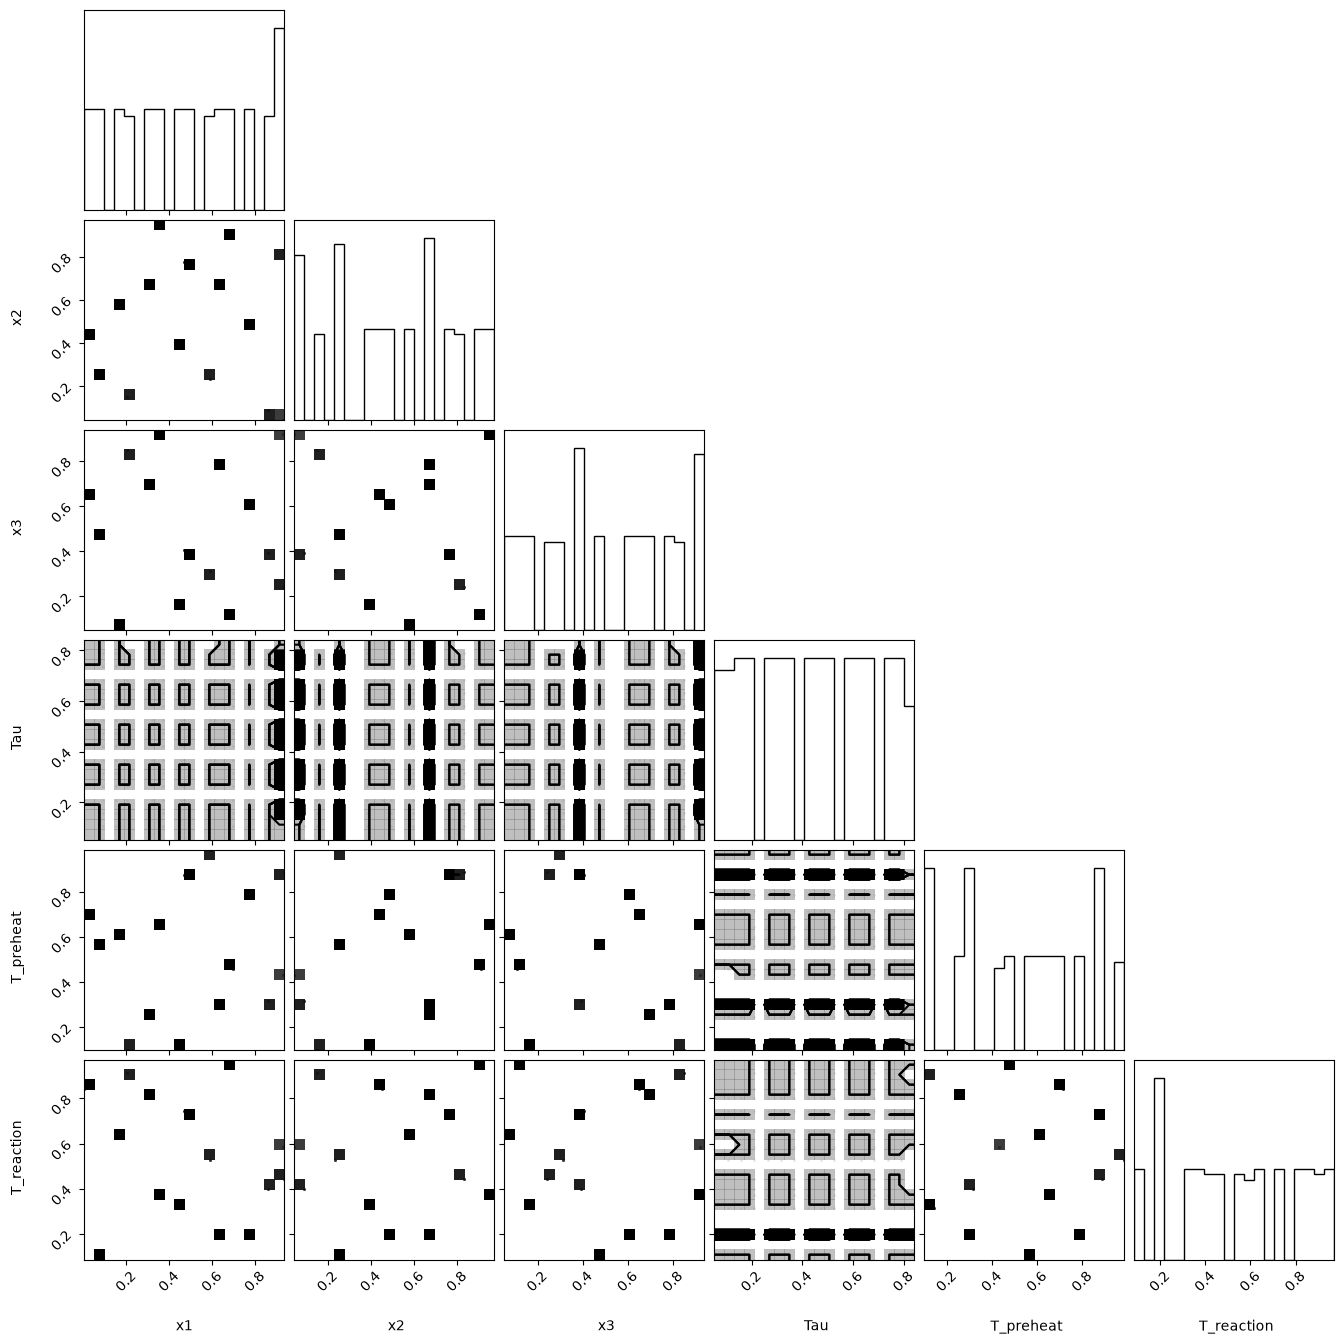

In [20]:
import corner

fig = corner.corner(inputs, labels=inputs.columns)

In [ ]:
# Single-objective Bayesian optimisation
from botorch.models.transforms import Normalize,Standardize
from botorch.fit import fit_gpytorch_mll
from gpytorch.mlls import ExactMarginalLogLikelihood
from botorch.acquisition.predictive_entropy_search import qPredictiveEntropySearch
from botorch.acquisition.joint_entropy_search import qJointEntropySearch
from botorch.acquisition.max_value_entropy_search import qMaxValueEntropy
from botorch.optim import optimize_acqf, optimize_acqf_discrete
from botorch.models import SingleTaskGP
from gpytorch.kernels import *
from tqdm import tqdm
import torch.nn as nn


acquf = 'qPredictiveEntropySearch'
kernel = 'RBFKernel'
break_after_finding_optimum = True


acquf_list = [
    'qPredictiveEntropySearch',
    'qJointEntropySearch',
    'qMaxValueEntropy'
]

kernel_list = [
    "keops",
    "Kernel",
    "ArcKernel",
    "AdditiveKernel",
    "AdditiveStructureKernel",
    "ConstantKernel",
    "CylindricalKernel",
    "MultiDeviceKernel",
    "CosineKernel",
    "DistributionalInputKernel",
    "GaussianSymmetrizedKLKernel",
    "GridKernel",
    "GridInterpolationKernel",
    "HammingIMQKernel",
    "IndexKernel",
    "InducingPointKernel",
    "LCMKernel",
    "LinearKernel",
    "MaternKernel",
    "MultitaskKernel",
    "NewtonGirardAdditiveKernel",
    "PeriodicKernel",
    "PiecewisePolynomialKernel",
    "PolynomialKernel",
    "PolynomialKernelGrad",
    "ProductKernel",
    "ProductStructureKernel",
    "RBFKernel",
    "RFFKernel",
    "RBFKernelGrad",
    "RBFKernelGradGrad",
    "RQKernel",
    "ScaleKernel",
    "SpectralDeltaKernel",
    "SpectralMixtureKernel",
    "Matern52KernelGrad",
]


torch.manual_seed(42)
MAE = nn.L1Loss() # Scikit-learn requires numpy arrays, so this is probably easier to use

optimisations = len(test_X)

target_preds = []

best_idx_global = test_y[:, 0].argmax()
global_optimal_inputs = test_X[best_idx_global].unsqueeze(0)
global_optimal_outputs = test_y[best_idx_global, 0].reshape(1, 1)

for i in tqdm(range(optimisations), total=optimisations, desc='Optimising'):
    
    # Calculate optimal inputs and outputs 
    # for Entropy-based acquisition functions
    best_idx = train_y[:, 0].argmax()

    optimal_inputs = train_X[best_idx].unsqueeze(0)
    optimal_outputs = train_y[best_idx, 0].reshape(1, 1)


    model=SingleTaskGP(train_X,train_y[:, 0].unsqueeze(1),
                    outcome_transform=Standardize(m=1),
                    covar_module=ScaleKernel(LinearKernel(train_X.shape[-1])),
                    )
    
    
    # Load chosen acquisition function
    if acquf == 'qPredictiveEntropySearch':
        acq = qPredictiveEntropySearch(model=model, optimal_inputs=optimal_inputs)
    elif acquf == 'qJointEntropySearch':
        acq = qJointEntropySearch(model=model, optimal_inputs=optimal_inputs, optimal_outputs=optimal_outputs)
    elif acquf == 'qMaxValueEntropy':
        acq = qMaxValueEntropy(model=model, candidate_set=train_X)
    else:
        print('Acquisition function not in list')
        break


    fit_gpytorch_mll(ExactMarginalLogLikelihood(model.likelihood,model))




    new_X,_=optimize_acqf_discrete( # Discrete acqf required to confine model to known experiments
                                    acq_function=acq, 
                                    choices=test_X,
                                    q=1,
    )


    # Remove selected data point from test, add to train
    hit = (test_X == new_X).all(dim=1)
    print(new_X)
    
    if test_y[hit][:, 0] == global_optimal_outputs.squeeze(0):
        print(f'Optimised after {i} iterations')
        if break_after_finding_optimum:
            break
    
    train_X = torch.cat((train_X, test_X[hit]))
    train_y = torch.cat((train_y, test_y[hit]))

    test_X = test_X[~hit]
    test_y = test_y[~hit]
    
    
    target_preds.append(model.posterior(external_test_X).mean) # Make predictions for external test set
    

/opt/anaconda3/envs/ml_BO/lib/python3.15/site-packages/torch/jit/_script.py:1485: FutureWarning: `torch.jit.script` is not supported in Python 3.14+ and may break. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
Optimising:   1%|          | 2/211 [00:00<01:03,  3.29it/s]

tensor([[0.6959, 0.9088, 0.1101, 0.4737, 0.4571, 0.9714]], dtype=torch.float64)
tensor([[0.6958, 0.9088, 0.1101, 0.4210, 0.4571, 0.9714]], dtype=torch.float64)


/opt/anaconda3/envs/ml_BO/lib/python3.15/site-packages/botorch/fit.py:241: OptimizationWarning: `scipy_minimize` terminated with status OptimizationStatus.FAILURE, displaying original message from `scipy.optimize.minimize`: ABNORMAL: 
  result = optimizer(mll, closure=closure, **optimizer_kwargs)
Optimising:   2%|▏         | 4/211 [00:00<00:40,  5.16it/s]

tensor([[0.6959, 0.9088, 0.1101, 0.5789, 0.4571, 0.9714]], dtype=torch.float64)
tensor([[0.6959, 0.9088, 0.1101, 0.8422, 0.4571, 0.9714]], dtype=torch.float64)


Optimising:   2%|▏         | 5/211 [00:01<00:47,  4.34it/s]

tensor([[0.6958, 0.9088, 0.1101, 0.7894, 0.4571, 0.9714]], dtype=torch.float64)


... (10 outputs left out)

/opt/anaconda3/envs/ml_BO/lib/python3.15/site-packages/botorch/fit.py:241: OptimizationWarning: `scipy_minimize` terminated with status OptimizationStatus.FAILURE, displaying original message from `scipy.optimize.minimize`: ABNORMAL: 
  result = optimizer(mll, closure=closure, **optimizer_kwargs)
Optimising:   7%|▋         | 15/211 [00:03<00:44,  4.36it/s]

tensor([[0.0043, 0.4521, 0.6494, 0.8420, 0.7143, 0.8429]], dtype=torch.float64)
tensor([[0.2024, 0.1495, 0.8483, 0.5790, 0.1000, 0.9143]], dtype=torch.float64)


Optimising:   7%|▋         | 15/211 [00:03<00:43,  4.46it/s]

tensor([[0.9279, 0.0451, 0.9210, 0.8421, 0.4286, 0.5857]], dtype=torch.float64)
Optimised after 15 iterations


/opt/anaconda3/envs/ml_BO/lib/python3.15/site-packages/torch/nn/modules/loss.py:133: UserWarning: Using a target size (torch.Size([22, 2])) that is different to the input size (torch.Size([22, 1])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.l1_loss(input, target, reduction=self.reduction)


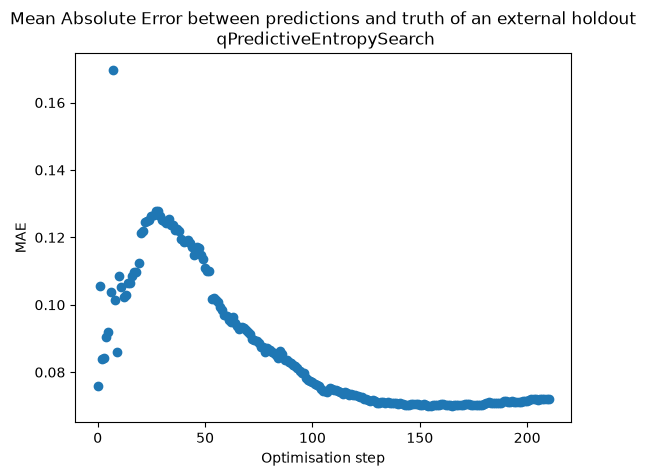

In [7]:
import matplotlib.pyplot as plt

MAEs = [MAE(pred, external_test_y).detach() for pred in target_preds]
plt.scatter(range(len(MAEs)), MAEs)
plt.title(f'Mean Absolute Error between model predictions and truth of an external holdout\n {outputs.columns[i]} \n {acquf}')
plt.xlabel('Optimisation step')
plt.ylabel('MAE')
plt.show()

In [4]:
# Multi-objective Bayesian optimisation
from botorch.models.transforms import Normalize,Standardize
from botorch.models import ModelListGP
from botorch.fit import fit_gpytorch_mll
from gpytorch.mlls import SumMarginalLogLikelihood
from botorch.acquisition.predictive_entropy_search import qPredictiveEntropySearch
from botorch.acquisition.joint_entropy_search import qJointEntropySearch
from botorch.acquisition.max_value_entropy_search import qMaxValueEntropy
from botorch.optim import optimize_acqf_discrete
from botorch.models import SingleTaskGP
from gpytorch.kernels import *
from tqdm import tqdm
import torch.nn as nn


acquf = 'qPredictiveEntropySearch'
kernel = 'RBFKernel'
break_after_finding_optimum = True


torch.manual_seed(42)
MAE = nn.L1Loss() # Scikit-learn requires numpy arrays, so this is probably easier to use

# optimisations = len(test_X)
optimisations = 200

target_preds = []

best_idx_global = test_y[:, :].argmax()
global_optimal_inputs = test_X[best_idx_global].unsqueeze(0)
global_optimal_outputs = test_y[best_idx_global, :]

for iter in tqdm(range(optimisations), total=optimisations, desc='Optimising'):
    
    # Calculate optimal inputs and outputs for Entropy-based acquisition functions

    models = []
    
    for feature in range(train_y.shape[-1]):
        best_idx = train_y[:, feature].argmax()

        optimal_inputs = train_X[best_idx].unsqueeze(0)
        optimal_outputs = train_y[best_idx, feature].reshape(1, 1)
        
        model=SingleTaskGP(train_X,train_y[:, feature].unsqueeze(1),
                        outcome_transform=Standardize(m=1),
                        # covar_module=ScaleKernel(LinearKernel(train_X.shape[-1])),
                        )
        models.append(model)
    
        # Load chosen acquisition function
        if acquf == 'qPredictiveEntropySearch':
            acq = qPredictiveEntropySearch(model=model, optimal_inputs=optimal_inputs)
        elif acquf == 'qJointEntropySearch':
            acq = qJointEntropySearch(model=model, optimal_inputs=optimal_inputs, optimal_outputs=optimal_outputs)
        elif acquf == 'qMaxValueEntropy':
            acq = qMaxValueEntropy(model=model, candidate_set=train_X)
        else:
            print('Acquisition function not in list')
            break


    model = ModelListGP(*models)

    fit_gpytorch_mll(SumMarginalLogLikelihood(model.likelihood,model))




    new_X,_=optimize_acqf_discrete( # Discrete acqf required to confine model to known experiments
                                    acq_function=acq, 
                                    choices=test_X,
                                    q=1,
    )


    # Remove selected data point from test, add to train
    hit = (test_X == new_X).all(dim=1)

    if torch.any(test_y[hit] == global_optimal_outputs):
        print(f'Optimised after {iter} iterations')
        if break_after_finding_optimum:
            break


    train_X = torch.cat((train_X, test_X[hit]))
    train_y = torch.cat((train_y, test_y[hit]))

    test_X = test_X[~hit]
    test_y = test_y[~hit]

    target_preds.append(model.posterior(external_test_X).mean) # Make predictions for external test set
    

Optimising:   0%|          | 0/200 [00:00<?, ?it/s]

Optimising:  41%|████      | 82/200 [00:27<00:39,  2.99it/s]

Optimised after 82 iterations


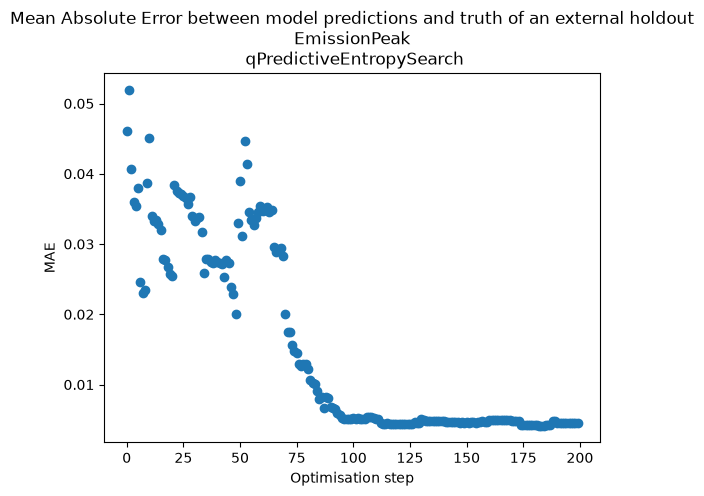

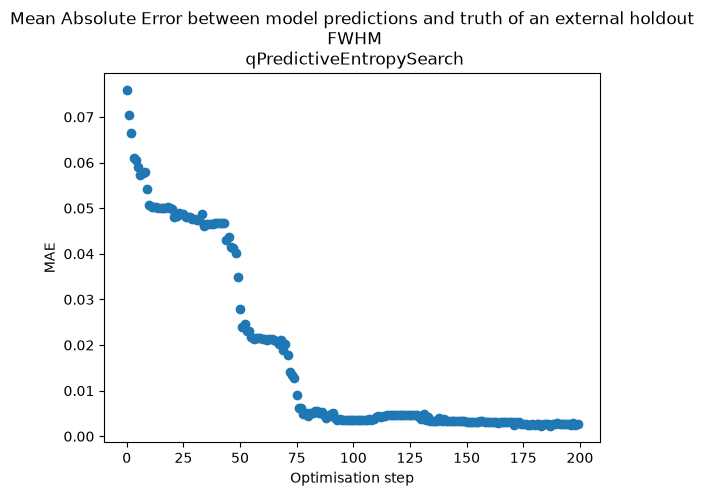

In [23]:
import matplotlib.pyplot as plt

for i in range(test_y.shape[-1]):
    MAEs = [MAE(pred[:, i], external_test_y[:, i]).detach() for pred in target_preds]
    plt.scatter(range(len(MAEs)), MAEs)
    plt.title(f'Mean Absolute Error between model predictions and truth of an external holdout\n {outputs.columns[i]} \n {acquf}')
    plt.xlabel('Optimisation step')
    plt.ylabel('MAE')
    plt.show()